# CAPTURE-24, part 2: a pretrained encoder and a model that sees minutes

Part 1 ([`capture24_har.ipynb`](capture24_har.ipynb)) ended with model B: a balanced random forest (model A) on 39 hand-made features of each 10 s window, smoothed over time by a hidden Markov model (HMM). B scores κ 0.690 on the 51 held-out participants, above a rerun of the paper's random forest + HMM (0.660) and below the paper's published CNN + HMM (0.735).

This notebook trains a better model in three steps, scores it on the held-out participants (section 4) and takes the gain apart (section 5).

1. **Where B goes wrong.** Two thirds of its errors are more than a minute from any label change, which suggests bouts of a few minutes misread by a classifier that sees 10 seconds at a time.
2. **A pretrained encoder.** `ssl-wearables` (Yuan et al., *npj Digital Medicine* 2024), a network the data's authors pretrained without labels on 700,000 person-days of UK Biobank wrist data, replaces the hand-made features. CAPTURE-24 was not part of its pretraining.
3. **Context from minutes.** A small recurrent network reads the encoder's output for about 10 minutes of consecutive windows and labels each one.

## Result

The best model, "Context", is the encoder used frozen with a bidirectional GRU over consecutive windows. Its design and the rule that picked it were written down before any of its scores were seen, and it was scored on the held-out participants once.

| Held-out participants [95% interval] | Macro-F1 | κ |
|---|---|---|
| The paper's random forest + HMM, rerun in part 1 | 0.535 [0.490, 0.566] | 0.660 [0.630, 0.692] |
| B: random forest + HMM (part 1) | 0.566 [0.524, 0.595] | 0.690 [0.653, 0.725] |
| Deep + HMM: the encoder fine-tuned, + B's HMM | 0.619 [0.557, 0.659] | 0.742 [0.702, 0.778] |
| **Context: the encoder frozen, + recurrent network** | **0.642 [0.577, 0.677]** | **0.790 [0.758, 0.819]** |
| Context minus B, paired by participant | +0.076 [0.021, 0.111] | +0.100 [0.076, 0.124] |
| Context minus Deep + HMM, paired by participant | +0.022 [−0.025, 0.057] | +0.048 [0.026, 0.071] |
| The paper's CNN + HMM, as published (not paired) | 0.576 | 0.735 |

![Held-out scores](outputs/results_new_model.png)

- **Context beats B** on both metrics, paired by participant, and **beats Deep + HMM on κ**. The paper's published κ is below Context's interval. That CNN was trained from scratch (Chan et al. list self-supervised learning as future work), so part of the gap is pretraining.
- **The gain comes from the encoder and the context together**, and they overlap (section 5): in cross-validation the encoder adds 0.034 to 0.070 κ over the hand-made features, and context adds 0.020 to 0.056.
- **Macro-F1 gains are smaller and less certain.** Rare activities (manual work, mixed activity) stay at F1 0.3 or below in cross-validation.
- **Part of the gap to B is the decision rule** (section 5). Context keeps the class frequencies in its output and the HMM models divide them out; with every model at its best rule, Context's cross-validation gain over B is 0.064 κ instead of 0.105.

**How to read the scores.** Macro-F1 is the average F1 per activity, so rare activities count as much as sleep; κ (Cohen's kappa) is agreement beyond chance. Every score is on labelled windows, and labelled windows almost never sit on a change of activity (section 1), so the scores describe the inside of bouts. Cross-validation ± figures are over five folds that share most of their training participants, so they understate the uncertainty; the paired bootstraps over held-out participants are the inference to lean on.

## Setup

Run part 1 first: this notebook reads its feature cache and `outputs/results.json`. Training needs a GPU. Every fit is cached in `data/fits/`; with every fit cached a run takes about 10 min. From scratch it fits 16 fine-tuned encoders (about 9 min each on an RTX 2070 SUPER) and 61 recurrent networks (3-5 min each).

In [1]:
import hashlib
import json
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

sys.path.insert(0, "scripts")
import deep
import features as F
import har
from deep import CONTEXT_LENGTH
from har import BLUE, CLASSES, CODES, GREEN, MUTED, ORANGE, PURPLE, SHOWN, fit_hmm, interval, metrics_from_cm, smooth

Settings. The training settings of each kind of fit live in `scripts/deep.py`, shared with `scripts/train_context.py`.

In [2]:
T0 = perf_counter()
SEED, N_FOLDS, N_BOOT, N_TREES = 42, 5, 2000, 300  # as in part 1
SEEDS = [42, 43, 44]
K = len(CODES)

DATA, OUT = Path("data"), Path("outputs")
RAW, FITS = DATA / "capture24", DATA / "fits"
STORE = DATA / f"windows30hz_w{F.WINSEC}s_v{F.FEATURE_VERSION}.npy"
STORE_START = DATA / f"windows30hz_w{F.WINSEC}s_v{F.FEATURE_VERSION}_start.npy"

SHARED = {"folds": f"{N_FOLDS} folds, seed {SEED}", "features": F.FEATURE_VERSION, "encoder": deep.REPO,
          "early stopping": f"a fifth of the training participants, seed {SEED}"}
FINE_TUNING, CONTEXT = deep.FINE_TUNING, deep.CONTEXT

har.set_style()

Part 1's window table and scores.

In [3]:
windows = pd.read_parquet(DATA / f"features_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet")
PART1 = json.loads((OUT / "results.json").read_text())
PUBLISHED = {f"{name}, published": PART1["paper"]["10-class"][name] for name in ("Paper RF + HMM", "Paper CNN + HMM")}
X = windows[F.FEATURE_NAMES].to_numpy()
Y = windows["10-class"].to_numpy()  # -1 = unlabelled
GROUPS = windows["participant"].to_numpy()
START = windows["window_start"].to_numpy()
LABELLED = Y >= 0
IS_DEV = GROUPS <= "P100"  # P101-P151 are held out

Every fit is saved in `data/fits/` under a name ending in a hash of its settings and of `SHARED`, so a changed setting means a new fit.

In [4]:
def cached(compute, **key):
    digest = hashlib.sha1(json.dumps(key | SHARED, sort_keys=True).encode()).hexdigest()[:8]
    path = FITS / f"{'_'.join(str(v) for v in key.values() if not isinstance(v, dict))}_{digest}.npy"
    if not path.exists():
        FITS.mkdir(exist_ok=True)
        np.save(path, compute())
    return np.load(path)

## 1. The baseline, and where its errors are

B is refitted here from `scripts/har.py`, the module part 1 uses, on the same five participant-grouped folds of P001-P100. Its HMM takes the forest's probabilities as the emission likelihood (Rabiner, 1989), decodes every window of a recording with Viterbi, labelled or not, and is scored on the labelled windows.

In [5]:
SEQ = har.sequence_ids(START, GROUPS)


def class_prior(train):
    return np.bincount(Y[train[LABELLED[train]]], minlength=K) / LABELLED[train].sum()


def forest_proba(train, test):
    labelled = train[LABELLED[train]]
    return har.balanced_forest(N_TREES, SEED).fit(X[labelled], Y[labelled]).predict_proba(X[test])


def hmm_predict(lik, train, test):
    return smooth(lik, SEQ[test], fit_hmm(Y[train], SEQ[train], K))[LABELLED[test]]

Every model below is scored the same way: a decision per fold (the top class, or the HMM path), then metrics per fold, and F1 per activity with the folds pooled.

In [6]:
def top_class(proba, test):
    return proba[LABELLED[test]].argmax(axis=1)


def hmm_cv(probas, divide=True):
    return [hmm_predict(proba / class_prior(train) if divide else proba, train, valid) for proba, (train, valid) in zip(probas, FOLDS)]


def top_class_cv(probas):
    return [top_class(proba, valid) for proba, (_, valid) in zip(probas, FOLDS)]


def cv_scores(preds):
    return pd.DataFrame([metrics_from_cm(confusion_matrix(Y[rows], pred, labels=range(K))) for rows, pred in zip(CV_ROWS, preds)])


def pooled_f1(preds):
    return metrics_from_cm(confusion_matrix(Y[np.concatenate(CV_ROWS)], np.concatenate(preds), labels=range(K)))["per_class_f1"]


def against(scores, baseline, name):
    change = scores[list(SHOWN)] - baseline[list(SHOWN)]
    return {f"{label} against {name}": f"{change[m].mean():+.3f} ± {change[m].sem():.3f}" for m, label in SHOWN.items()}

Part 1's folds and forests, refitted. B's cross-validation scores must match part 1's.

In [7]:
FOLDS = list(har.participant_folds(Y, GROUPS, np.flatnonzero(IS_DEV & LABELLED), N_FOLDS, SEED))
CV_ROWS = [valid[LABELLED[valid]] for _, valid in FOLDS]
FOREST_CV = [forest_proba(train, valid) for train, valid in FOLDS]
CV_PRED = {"A": top_class_cv(FOREST_CV), "B": hmm_cv(FOREST_CV, divide=False)}
B_CV = cv_scores(CV_PRED["B"])
assert np.allclose([B_CV[m].mean() for m in SHOWN], [PART1["tasks"]["10-class"]["B"]["cv"][m]["mean"] for m in SHOWN])
B_CV[list(SHOWN)].mean().rename(SHOWN).round(3)

macro-F1    0.522
κ           0.708
dtype: float64

Labels come from camera frames 20-40 s apart, so the moment an activity changes is uncertain. If B's errors sit next to label changes, part of the gap to a perfect score is label timing, which no model can recover. If they sit inside bouts, a better classifier can fix them. For every labelled window, the cell below measures the time to the nearest change of label in its recording (to or from "unlabelled" included).

In [8]:
DISTANCE = har.windows_to_change(Y, SEQ)
BINS = {"0-10 s": (0, 0), "10-30 s": (1, 2), "30-60 s": (3, 5), "1-5 min": (6, 29), "over 5 min": (30, 10**9)}
MID_ERROR = "error rate 1-5 min from a change"


def in_bin(rows, name):
    lo, hi = BINS[name]
    return (DISTANCE[rows] >= lo) & (DISTANCE[rows] <= hi)


MID = [in_bin(rows, "1-5 min") for rows in CV_ROWS]


def error_by_distance():
    rows = np.concatenate(CV_ROWS)
    wrong = {m: np.concatenate(CV_PRED[m]) != Y[rows] for m in ("A", "B")}
    table = {}
    for name in BINS:
        here = in_bin(rows, name)
        table[name] = {"A error rate": wrong["A"][here].mean(), "B error rate": wrong["B"][here].mean(),
                       "share of windows": here.mean(), "share of B's errors": wrong["B"][here].sum() / wrong["B"].sum()}
    return pd.DataFrame(table).T


def mid_error(preds):
    return np.mean([(pred[mid] != Y[rows][mid]).mean() for pred, rows, mid in zip(preds, CV_ROWS, MID)])

**Figure 1.** Error rate of A and B by time to the nearest label change, with each bin's share of windows.

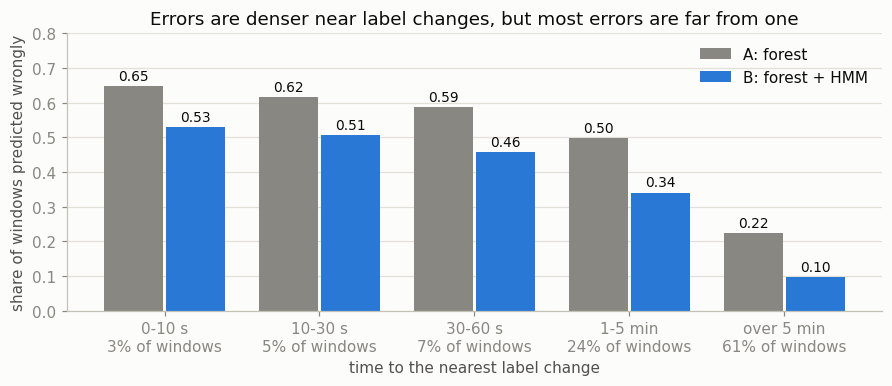

In [9]:
def plot_error_by_distance(table):
    fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
    x = np.arange(len(table))
    for offset, model, label, color in ((-0.2, "A", "A: forest", MUTED), (0.2, "B", "B: forest + HMM", BLUE)):
        bars = ax.bar(x + offset, table[f"{model} error rate"], width=0.38, color=color, label=label)
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    ax.set_xticks(x, [f"{name}\n{share:.0%} of windows" for name, share in table["share of windows"].items()])
    ax.set(xlabel="time to the nearest label change", ylabel="share of windows predicted wrongly", ylim=(0, 0.8),
           title="Errors are denser near label changes, but most errors are far from one")
    ax.grid(axis="x", visible=False)
    ax.legend()
    fig.savefig(OUT / "error_by_distance.png", dpi=150)


ERRORS = error_by_distance()
plot_error_by_distance(ERRORS)

**Table 1.** B's scores with the windows within 30 s of a change left out, then the bins of Figure 1 in numbers.

In [10]:
beyond_30s = [DISTANCE[rows] >= 3 for rows in CV_ROWS]
away = pd.DataFrame([metrics_from_cm(confusion_matrix(Y[rows][f], pred[f], labels=range(K)))
                     for rows, pred, f in zip(CV_ROWS, CV_PRED["B"], beyond_30s)])
print(pd.DataFrame({"all labelled windows": B_CV[list(SHOWN)].mean(),
                    "more than 30 s from a change": away[list(SHOWN)].mean()}).rename(index=SHOWN).round(3).to_string())
ERRORS.round(3)

          all labelled windows  more than 30 s from a change
macro-F1                 0.522                         0.533
κ                        0.708                         0.737


,A error rate,B error rate,share of windows,share of B's errors
0-10 s,0.647,0.530,0.027,0.068
10-30 s,0.617,0.507,0.053,0.127
30-60 s,0.587,0.458,0.066,0.141
1-5 min,0.498,0.341,0.244,0.390
over 5 min,0.223,0.096,0.609,0.274


Errors are denser near label changes: B is wrong on 53% of windows within 10 s of a change and on 10% of windows more than 5 min from one. But few windows are near a change. Those within 30 s are 8% of windows and 19% of B's errors, and scoring B without them raises κ from 0.708 to 0.737. So uncertain label timing explains at most about 0.03 κ.

Two thirds of B's errors are more than a minute from any change, and the 1-5 min bin holds the largest share, 39%. That suggests bouts of a few minutes that B gets wrong as a whole, though distance to a change cannot show it directly. A model that sees more than 10 s at a time could fix those. The error rate 1-5 min from a change is tracked for every model below.

Why so few windows sit near a change: how the labelled runs end in P001-P100.

In [11]:
adjacent = (SEQ[1:] == SEQ[:-1]) & IS_DEV[1:]
both = adjacent & LABELLED[1:] & LABELLED[:-1]
change = adjacent & (Y[1:] != Y[:-1])
trans = fit_hmm(Y[IS_DEV], SEQ[IS_DEV], K)["trans"]
print(f"adjacent pairs of labelled windows: {both.sum():,}; of those, two different activities: {(both & change).sum()}")
print(f"label changes: {change.sum():,}; into or out of 'unlabelled': {(change & ~both).sum():,}")
print(f"B's transition matrix: {(trans[~np.eye(K, dtype=bool)] == 0).sum()} of {K * (K - 1)} off-diagonal entries are zero")

adjacent pairs of labelled windows: 609,580; of those, two different activities: 46
label changes: 16,948; into or out of 'unlabelled': 16,902
B's transition matrix: 72 of 90 off-diagonal entries are zero


Annotators leave an unlabelled gap at almost every change of activity: only 46 of 609,580 adjacent pairs of labelled windows are two different activities. B counts transitions between adjacent labelled windows only, so most of its transition matrix is zero and it comes out close to "never switch unless the forest insists". The matrix is fitted on training participants only, so this is no leak. It is a property of how the labels were made. It makes B's HMM a strong flicker filter, and it is why the scores above describe the inside of bouts.

## 2. A pretrained encoder

**Model.** `harnet10` from `ssl-wearables` (Yuan et al., 2024): an 18-layer 1D ResNet (He et al., 2016) with about 11M parameters, pretrained without labels on 700,000 person-days of UK Biobank wrist data (Doherty et al., 2017). No CAPTURE-24 data was used to pretrain it. Its authors did use CAPTURE-24 as one of seven downstream benchmarks, with 4 classes: fine-tuned, it scored subject-wise F1 0.726 and κ 0.737 there, against 0.708 and 0.703 for the same network trained from scratch. They also compared pretraining tasks on it and two other datasets, found no clear best and kept all tasks. Those numbers are not comparable to the 10-class task here, and no 10-class result for this encoder was found in the literature. It takes 10 s at 30 Hz, so each window is resized from 1,000 to 300 samples by linear interpolation, as its authors do, and stored once.

**Fine-tuning settings, fixed before any score was seen**, with the encoder's authors' settings where they give them: all layers, Adam (Kingma & Ba, 2015) in its AMSGrad variant (Reddi et al., 2018) with learning rate 1e-4, batches of 1,000 windows, no augmentation. A fifth of the training participants are held out for early stopping (Prechelt, 1998): training stops when their loss has not improved for 5 epochs, and the best epoch is kept. Three seeds per fold.

**Feeding a network to an HMM.** B's HMM works because a balanced forest's output is roughly proportional to P(window | activity). A network trained with cross-entropy outputs P(activity | window), which already contains how common each activity is, so its softmax is divided by the training class frequencies before the HMM (Bourlard & Morgan, 1994). An earlier version of this notebook also tried class-balanced batches and transitions counted across unlabelled gaps; the HMM variant was then chosen on cross-validation: dividing by the prior with B's transitions was best on macro-F1 (by 0.001), and passing the softmax undivided cost 0.074 macro-F1. That comparison is in the repository history (commit `2e6492d`).

Every window resampled to 30 Hz, stored once on disk and read as needed.

In [12]:
if not STORE.exists():
    deep.build_store(sorted(RAW.glob("P[0-9][0-9][0-9].csv.gz")), len(windows), STORE, STORE_START)
X30 = np.load(STORE, mmap_mode="r")  # (windows, 3, 300) float16, memory-mapped
assert (np.load(STORE_START) == START).all(), "the 30 Hz store does not line up with the feature cache"

The fine-tuning fit, run with three seeds on each fold.

In [13]:
def early_stopping_split(train):
    """A fifth of the training participants, held out for early stopping; the same for every kind of fit and seed."""
    return har.early_stopping_split(Y, GROUPS, train, SEED)


def fine_tuned(split, train, test, seed=SEED):
    def fit():
        fit_rows, val_rows = (rows[LABELLED[rows]] for rows in early_stopping_split(train))
        model = deep.fine_tune(X30, Y, fit_rows, val_rows, seed, **FINE_TUNING)
        return deep.encoder_proba(model, X30, test)
    return cached(fit, model="fine-tuned", variant="natural", split=split, seed=seed, settings=FINE_TUNING)


DEEP_CV = {seed: [fine_tuned(f"fold{i}", train, valid, seed) for i, (train, valid) in enumerate(FOLDS)] for seed in SEEDS}

The frozen encoder's output for every window, computed once and stored on disk.

In [14]:
if not deep.EMBEDDINGS.exists():
    deep.build_embeddings(X30, deep.EMBEDDINGS)
EMBEDDED = np.load(deep.EMBEDDINGS, mmap_mode="r")  # (windows, 1024) float16, memory-mapped

## 3. A model that sees minutes

Section 1 says most of B's errors are whole bouts of a few minutes. So: **does context from minutes recover the bouts that a single-window model misreads?** This text, up to the held-out scores, was written before any score of the new model was seen.

**Model.** Every window goes once through the encoder as downloaded, never trained on CAPTURE-24 labels, which gives 1,024 numbers per window. A 2-layer bidirectional GRU (Cho et al., 2014; Schuster & Paliwal, 1997) with 128 units per direction and dropout 0.5 (Srivastava et al., 2014) reads them for consecutive windows and outputs an activity for each. It trains on chunks of 64 consecutive windows (about 10 min), a new chunk every 32 windows; unlabelled windows are part of the input and carry no loss. At prediction it reads each whole recording.

**Control.** The same network on single windows, followed by B's HMM. It shares the frozen encoder, so the difference between the two is context.

**Settings.** Adam with learning rate 1e-3, 16,384 windows per batch, early stopping on the same participants as the fine-tuning (5 epochs without improvement), natural class frequencies, three seeds per fold, the same five folds.

**Selection.** Two candidates: the context model's top class, and its softmax ÷ prior through B's HMM. The one with the higher cross-validation macro-F1 (mean over seeds) is scored on the held-out participants, once, with seed 42; if they are within 0.005, the higher κ decides.

The recurrent network's fit, for the context model and the single-window control, three seeds each, on every fold.

In [15]:
LENGTHS = {1: "single windows", CONTEXT_LENGTH: f"{CONTEXT_LENGTH} windows of context"}


def context_fit(inputs, length, split, train, test, seed=SEED):
    def fit():
        Z = EMBEDDED if inputs == "encoder" else scaled_features(train)
        model = deep.fit_context(Z, Y, SEQ, *early_stopping_split(train), length, seed, **CONTEXT)
        return deep.context_proba(model, Z, SEQ, test, length)
    return cached(fit, model="context", inputs=inputs, length=length, split=split, seed=seed, settings=CONTEXT)


def context_cv(inputs, length, seed):
    return [context_fit(inputs, length, f"fold{i}", train, valid, seed) for i, (train, valid) in enumerate(FOLDS)]


CONTEXT_CV = {(length, seed): context_cv("encoder", length, seed) for length in LENGTHS for seed in SEEDS}

Each model's per-fold scores averaged over seeds, the spread over seeds, and the error rate 1-5 min from a label change.

In [16]:
def summary(by_seed):
    per_seed = pd.DataFrame([{**cv_scores(preds)[list(SHOWN)].mean().rename(SHOWN), MID_ERROR: mid_error(preds)} for preds in by_seed])
    fold_mean = sum(cv_scores(preds)[list(SHOWN)] for preds in by_seed) / len(by_seed)
    spread = {f"{label}, spread over seeds": per_seed[label].std() for label in SHOWN.values()}
    return fold_mean, {**per_seed.mean(), **spread}


MODELS = {"B": [CV_PRED["B"]], "Deep + HMM": [hmm_cv(probas) for probas in DEEP_CV.values()]}
MODELS |= {f"frozen encoder, {label}{suffix}": [decide(CONTEXT_CV[length, seed]) for seed in SEEDS]
           for length, label in LENGTHS.items() for suffix, decide in (("", top_class_cv), (" + HMM", hmm_cv))}
SUMMARY = {name: summary(by_seed) for name, by_seed in MODELS.items()}
CV = {name: fold_mean for name, (fold_mean, _) in SUMMARY.items()}

The selection rule, fixed before any score: the higher cross-validation macro-F1; within 0.005 of each other, the higher κ.

In [17]:
ALONE, WITH_HMM = (f"frozen encoder, {LENGTHS[CONTEXT_LENGTH]}{suffix}" for suffix in ("", " + HMM"))
TIE = abs(CV[ALONE]["macro_f1"].mean() - CV[WITH_HMM]["macro_f1"].mean()) < 0.005
CONTEXT_CHOSEN = max((ALONE, WITH_HMM), key=lambda name: CV[name]["kappa" if TIE else "macro_f1"].mean())
print("chosen for the held-out participants:", CONTEXT_CHOSEN, "(by κ: within 0.005 macro-F1)" if TIE else "")

chosen for the held-out participants: frozen encoder, 64 windows of context (by κ: within 0.005 macro-F1)


**Table 2.** Every model in cross-validation: scores, the error rate 1-5 min from a label change, spread over seeds, and the change against B and against the fine-tuned encoder + HMM (mean ± standard error over folds).

In [18]:
CV_TABLE = pd.DataFrame({name: row for name, (_, row) in SUMMARY.items()}).T
CV_TABLE = CV_TABLE.join(pd.DataFrame({name: {**against(s, CV["B"], "B"), **(against(s, CV["Deep + HMM"], "Deep + HMM") if name != "Deep + HMM" else {})}
                                       for name, s in CV.items() if name != "B"}).T)
CV_TABLE.map(lambda v: round(v, 3) if isinstance(v, float) else v).fillna("")

,macro-F1,κ,error rate 1-5 min from a change,"macro-F1, spread over seeds","κ, spread over seeds",macro-F1 against B,κ against B,macro-F1 against Deep + HMM,κ against Deep + HMM
B,0.522,0.708,0.341,,,,,,
Deep + HMM,0.578,0.741,0.286,0.008,0.01,+0.056 ± 0.018,+0.033 ± 0.003,,
"frozen encoder, single windows",0.488,0.668,0.330,0.002,0.0,-0.034 ± 0.017,-0.040 ± 0.014,-0.090 ± 0.012,-0.073 ± 0.015
"frozen encoder, single windows + HMM",0.603,0.776,0.250,0.003,0.002,+0.081 ± 0.029,+0.068 ± 0.014,+0.025 ± 0.016,+0.035 ± 0.014
"frozen encoder, 64 windows of context",0.580,0.814,0.209,0.011,0.001,+0.058 ± 0.028,+0.105 ± 0.014,+0.002 ± 0.016,+0.072 ± 0.014
"frozen encoder, 64 windows of context + HMM",0.584,0.766,0.284,0.007,0.011,+0.062 ± 0.024,+0.058 ± 0.013,+0.006 ± 0.009,+0.025 ± 0.012


All rows but B are means over the same three seeds; the spread over seeds is at most 0.011.

- **Context does what it was built for.** The error rate 1-5 min from a label change is 0.21, against 0.34 for B, 0.29 for the fine-tuned encoder + HMM and 0.25 for the single-window control + HMM. κ is 0.814, +0.105 against B and +0.072 against the fine-tuned encoder + HMM on the same folds.
- **Macro-F1 moves less.** Context is +0.058 above B and level with the fine-tuned encoder + HMM (0.580 against 0.578).
- **The HMM no longer helps.** On top of the context model it lowers κ from 0.814 to 0.766 and leaves macro-F1 where it was: once the network removes the flicker itself, B's near "never switch" matrix only holds activities too long. The two candidates are within 0.005 macro-F1, so the higher κ decides, and the context model alone goes to the held-out participants.
- **Frozen is at least as good as fine-tuned here.** The single-window control (frozen encoder + HMM) scores macro-F1 0.603 and κ 0.776, against 0.578 and 0.741 for the fine-tuned encoder + HMM, though the two also have different heads. This fine-tuning recipe (best epoch the first or second, commit `2e6492d`) did not beat a small network on the frozen encoder. The encoder's authors report fine-tuning slightly ahead of a frozen encoder, so this is more likely a finding about the recipe. A gentler schedule was not tried.

## 4. Held-out participants

B, the fine-tuned encoder + HMM and the chosen context model are fitted on P001-P100 with seed 42 and scored once on P101-P151. B must reproduce part 1's held-out scores. Intervals are 95% percentile bootstraps over participants (2,000 draws; Efron & Tibshirani, 1993; Field & Welsh, 2007), and differences between models are paired: the same draws of participants for both.

In [19]:
DEV, TEST = np.flatnonzero(IS_DEV), np.flatnonzero(~IS_DEV)
SCORED = TEST[LABELLED[TEST]]
CONTEXT_MODEL = "Context + HMM" if CONTEXT_CHOSEN == WITH_HMM else "Context"
DEEP_TEST = fine_tuned("holdout", DEV, TEST)
CONTEXT_TEST = context_fit("encoder", CONTEXT_LENGTH, "holdout", DEV, TEST)
HOLDOUT_PRED = {"B": hmm_predict(forest_proba(DEV, TEST), DEV, TEST),
                "Deep + HMM": hmm_predict(DEEP_TEST / class_prior(DEV), DEV, TEST),
                CONTEXT_MODEL: (hmm_predict(CONTEXT_TEST / class_prior(DEV), DEV, TEST) if CONTEXT_MODEL == "Context + HMM"
                                else top_class(CONTEXT_TEST, TEST))}

Held-out scores with participant-bootstrap intervals, and paired differences on the same bootstrap draws.

In [20]:
def holdout_cms(pred):
    return har.participant_cms(Y[SCORED], pred, GROUPS[SCORED], K)


def score_holdout(pred):
    cms = holdout_cms(pred)
    point, draws = metrics_from_cm(cms.sum(axis=0)), har.bootstrap_metrics(cms, N_BOOT, SEED)
    return {**{m: interval(point[m], draws[m]) for m in SHOWN}, "per_class_f1": point["per_class_f1"]}


def paired_gain(pred, baseline):
    return har.paired_gain(holdout_cms(pred), holdout_cms(baseline), SHOWN, N_BOOT, SEED)


SCORES = {model: score_holdout(pred) for model, pred in HOLDOUT_PRED.items()}
assert np.allclose([SCORES["B"][m]["value"] for m in SHOWN], [PART1["tasks"]["10-class"]["B"]["holdout"][m]["value"] for m in SHOWN])
GAINS = {f"{model} minus {base}": paired_gain(HOLDOUT_PRED[model], HOLDOUT_PRED[base])
         for model, base in (("Deep + HMM", "B"), (CONTEXT_MODEL, "B"), (CONTEXT_MODEL, "Deep + HMM"))}

**Table 3.** Held-out scores [95% interval] and paired differences.

In [21]:
cell = lambda s, sign="": f"{s['value']:{sign}.3f} [{s['ci'][0]:{sign}.3f}, {s['ci'][1]:{sign}.3f}]"
pd.DataFrame({**{model: {label: cell(s[m]) for m, label in SHOWN.items()} for model, s in SCORES.items()},
              **{name: {label: cell(gain[m], "+") for m, label in SHOWN.items()} for name, gain in GAINS.items()}}).T

,macro-F1,κ
B,"0.566 [0.524, 0.595]","0.690 [0.653, 0.725]"
Deep + HMM,"0.619 [0.557, 0.659]","0.742 [0.702, 0.778]"
Context,"0.642 [0.577, 0.677]","0.790 [0.758, 0.819]"
Deep + HMM minus B,"+0.053 [+0.013, +0.085]","+0.052 [+0.029, +0.074]"
Context minus B,"+0.076 [+0.021, +0.111]","+0.100 [+0.076, +0.124]"
Context minus Deep + HMM,"+0.022 [-0.025, +0.057]","+0.048 [+0.026, +0.071]"


**Figure 2.** Held-out macro-F1 and κ with 95% intervals. Diamonds are the cross-validation means; grey bars are the paper's published numbers.

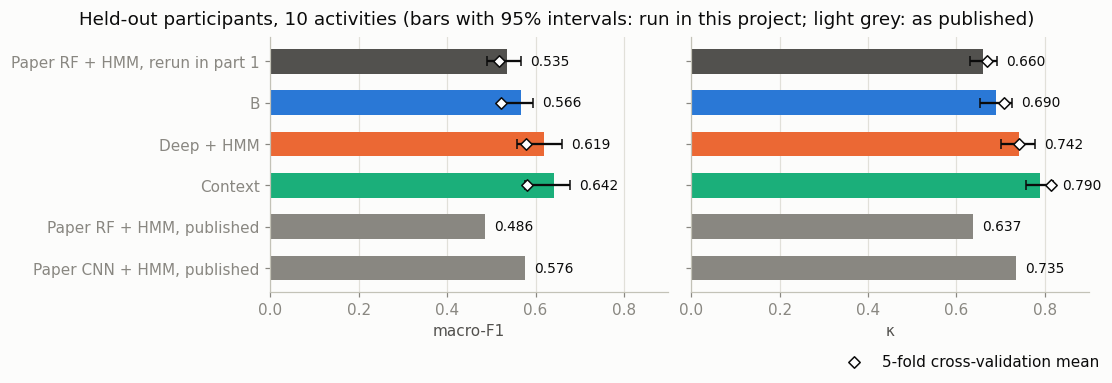

In [22]:
RERUN = PART1["paper_copy_10-class"]
# name -> (held-out scores, cross-validation means, colour)
SHOWN_MODELS = {"Paper RF + HMM, rerun in part 1": (RERUN["holdout"], {m: RERUN["cv"][m]["mean"] for m in SHOWN}, "#52514e"),
                "B": (SCORES["B"], CV["B"][list(SHOWN)].mean(), BLUE),
                "Deep + HMM": (SCORES["Deep + HMM"], CV["Deep + HMM"][list(SHOWN)].mean(), ORANGE),
                CONTEXT_MODEL: (SCORES[CONTEXT_MODEL], CV[CONTEXT_CHOSEN][list(SHOWN)].mean(), GREEN)}
title = "Held-out participants, 10 activities (bars with 95% intervals: run in this project; light grey: as published)"
har.plot_holdout(SHOWN_MODELS, PUBLISHED, title).savefig(OUT / "results_new_model.png", dpi=150)

**Table 4.** F1 per activity for B, the fine-tuned encoder + HMM and the context model, in cross-validation (folds pooled; seed 42 for the networks) and held out.

In [23]:
pd.DataFrame({**{f"{name} CV": pooled_f1(MODELS[key][0]) for name, key in (("B", "B"), ("Deep + HMM", "Deep + HMM"), (CONTEXT_MODEL, CONTEXT_CHOSEN))},
              **{f"{model} held out": s["per_class_f1"] for model, s in SCORES.items()}}, index=CODES).loc[CLASSES].round(3)

,B CV,Deep + HMM CV,Context CV,B held out,Deep + HMM held out,Context held out
sleep,0.970,0.963,0.992,0.980,0.971,0.993
sitting,0.861,0.879,0.937,0.873,0.897,0.928
standing,0.277,0.365,0.312,0.300,0.379,0.348
household-chores,0.596,0.630,0.701,0.531,0.609,0.631
manual-work,0.146,0.199,0.012,0.072,0.084,0.212
walking,0.422,0.521,0.548,0.426,0.492,0.546
mixed-activity,0.184,0.213,0.288,0.136,0.374,0.340
vehicle,0.792,0.880,0.883,0.733,0.950,0.966
sports,0.251,0.452,0.299,0.802,0.663,0.604
bicycling,0.820,0.913,0.872,0.810,0.776,0.851


On the held-out participants the context model scores macro-F1 0.642 (95% interval 0.577 to 0.677) and κ 0.790 (0.758 to 0.819).

- **Against B, paired:** +0.100 κ (0.076 to 0.124) and +0.076 macro-F1 (0.021 to 0.111).
- **Against the fine-tuned encoder + HMM, paired:** +0.048 κ (0.026 to 0.071) and +0.022 macro-F1 (−0.025 to 0.057), which is not reliable. As in cross-validation: more agreement, about the same macro-F1. The fine-tuned encoder + HMM is itself above B: +0.052 κ (0.029 to 0.074) and +0.053 macro-F1 (0.013 to 0.085).
- **Against the paper's CNN + HMM**, not paired: its published κ, 0.735, is below Context's interval, and its macro-F1, 0.576, just below the interval's lower edge (0.577). Read it as above on κ and unproven on macro-F1.
- **By activity it trades rare activities for common ones.** Against the fine-tuned encoder + HMM, in cross-validation it gains on sleep, sitting, household chores, walking and mixed activity and loses on manual work (F1 0.012 against 0.199), sports, standing and bicycling. That is why κ rises more than macro-F1. On the held-out participants manual work, bicycling and mixed activity go the other way, which shows how unstable rare activities are with 51 participants.

Cross-validation macro-F1, 0.580, is the safer figure to quote than the held-out 0.642: the held-out figure is pooled over participants and leans on activities only a few of them did (8 of the 51 did sports).

## 5. What the gain is made of

The comparisons above mix two things: the model, and the rule that turns its output into a class. Context keeps the class frequencies in its output, which favours common activities and κ; the HMM models have them divided out, which favours rare activities and macro-F1. So every model is scored here with its output ÷ prior^α (Saerens et al., 2002), from α = 0 (frequencies kept) to α = 1 (removed), on the cross-validation folds, averaged over three seeds (B has one fit).

To separate the encoder from the context, the same two networks, single-window + HMM and 64-window context, are also trained on B's 39 hand-made features, standardised with each fold's training participants. They were added after the held-out scores above, so they are scored in cross-validation only, and their settings were copied unchanged from the encoder networks, with no tuning of their own.

The two networks on the hand-made features, three seeds each on every fold.

In [24]:
def scaled_features(train):
    mean, sd = X[train].mean(axis=0), X[train].std(axis=0)
    return ((X - mean) / sd).astype(np.float32)


FEATURE_CV = {(length, seed): context_cv("features", length, seed) for length in LENGTHS for seed in SEEDS}

Every model's cross-validation scores as its output is divided by the class prior to the power α.

In [25]:
ALPHAS = [0, 0.25, 0.5, 0.75, 1]
MANUAL = CODES.index("manual-work")
# name -> (one list of fold outputs per seed, HMM, forest, colour, line style, alpha used in sections 3 and 4)
CURVES = {"B": ([FOREST_CV], True, True, BLUE, "-", 1),
          "Deep + HMM": (list(DEEP_CV.values()), True, False, ORANGE, "-", 1),
          "Single windows + HMM": ([CONTEXT_CV[1, seed] for seed in SEEDS], True, False, PURPLE, "-", 1),
          "Context": ([CONTEXT_CV[CONTEXT_LENGTH, seed] for seed in SEEDS], False, False, GREEN, "-", 0),
          "Context + HMM": ([CONTEXT_CV[CONTEXT_LENGTH, seed] for seed in SEEDS], True, False, GREEN, "--", 1),
          "Hand-made features, single windows + HMM": ([FEATURE_CV[1, seed] for seed in SEEDS], True, False, PURPLE, ":", None),
          "Hand-made features, context": ([FEATURE_CV[CONTEXT_LENGTH, seed] for seed in SEEDS], False, False, GREEN, ":", None)}


def prior_curve(by_seed, hmm, forest):
    """Cross-validation scores, mean over seeds, with the class frequencies removed to the power alpha: output ÷ prior^alpha.
    A balanced forest's output has them removed already, so there they are put back: output × prior^(1 - alpha)."""
    curve = {}
    for alpha in ALPHAS:
        per_seed = []
        for probas in by_seed:
            liks = [proba * class_prior(train) ** (1 - alpha if forest else -alpha) for proba, (train, _) in zip(probas, FOLDS)]
            preds = hmm_cv(liks, divide=False) if hmm else top_class_cv(liks)
            per_seed.append({**cv_scores(preds)[list(SHOWN)].mean().rename(SHOWN), "F1 for manual work": pooled_f1(preds)[MANUAL]})
        curve[alpha] = pd.DataFrame(per_seed).mean()
    return pd.DataFrame(curve).T


RULE = {name: prior_curve(by_seed, hmm, forest) for name, (by_seed, hmm, forest, *_) in CURVES.items()}

**Figure 3.** Macro-F1 against κ for each model as the decision rule moves from class frequencies kept (α = 0) to removed (α = 1). Rings mark the rule each model used in sections 3 and 4; dotted lines are the same networks on B's hand-made features, which have no ring because they were never scored held out.

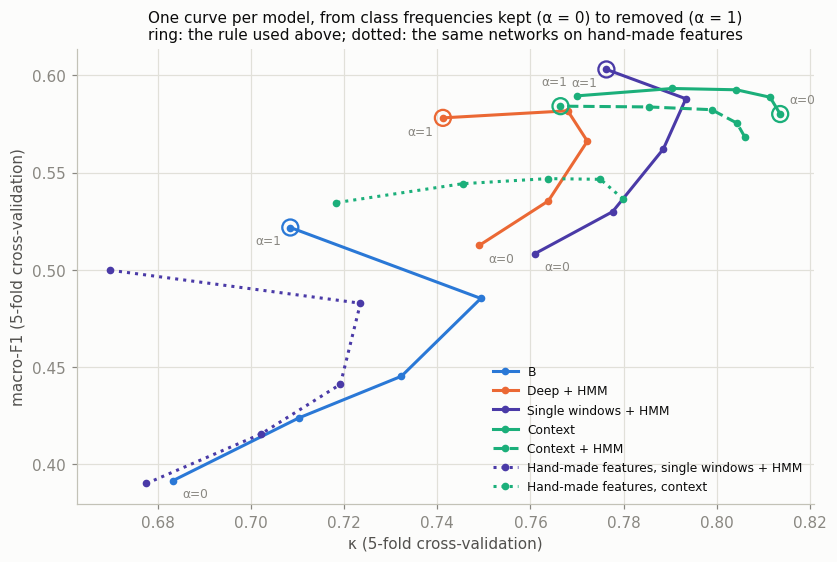

In [26]:
def plot_rule_curves():
    fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
    for name, (*_, color, style, used) in CURVES.items():
        curve = RULE[name]
        ax.plot(curve["κ"], curve["macro-F1"], color=color, linestyle=style, linewidth=2, marker="o", markersize=4, label=name)
        if used is not None:
            ax.scatter(*curve.loc[used, ["κ", "macro-F1"]], s=110, facecolor="none", edgecolor=color, linewidth=1.5, zorder=3)
        if style == "-":
            for alpha, dx in ((0, 6), (1, -6)):
                ax.annotate(f"α={alpha}", curve.loc[alpha, ["κ", "macro-F1"]], xytext=(dx, 7 if name == "Context" else -11),
                            textcoords="offset points", ha="left" if dx > 0 else "right", fontsize=8, color=MUTED)
    ax.set(xlabel="κ (5-fold cross-validation)", ylabel="macro-F1 (5-fold cross-validation)")
    ax.set_title("One curve per model, from class frequencies kept (α = 0) to removed (α = 1)\n"
                 "ring: the rule used above; dotted: the same networks on hand-made features", fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
    fig.savefig(OUT / "decision_rule.png", dpi=150)


plot_rule_curves()

**Table 5.** Each model at its best rule for κ and at its best rule for macro-F1.

In [27]:
BEST = pd.DataFrame({name: {"best κ": curve["κ"].max(), "macro-F1 there": curve.loc[curve["κ"].idxmax(), "macro-F1"],
                            "best macro-F1": curve["macro-F1"].max(), "κ there": curve.loc[curve["macro-F1"].idxmax(), "κ"]}
                     for name, curve in RULE.items()}).T
BEST.round(3)

,best κ,macro-F1 there,best macro-F1,κ there
B,0.749,0.485,0.522,0.708
Deep + HMM,0.772,0.566,0.582,0.768
Single windows + HMM,0.793,0.588,0.603,0.776
Context,0.814,0.580,0.593,0.790
Context + HMM,0.806,0.568,0.584,0.766
"Hand-made features, single windows + HMM",0.724,0.483,0.500,0.670
"Hand-made features, context",0.780,0.536,0.547,0.764


At each model's best rule for κ: Context 0.814, Context + HMM 0.806, single windows + HMM 0.793, hand-made features with context 0.780, Deep + HMM 0.772, B 0.749, hand-made features with single windows + HMM 0.724.

- **Context's gain over B shrinks to 0.064 κ** at each model's best rule, from 0.105 at the rules used above. About 40% of the cross-validation gap is the decision rule; the rest is the model.
- **The encoder and context both matter, and they overlap.** On B's hand-made features the two networks score 0.724 and 0.780; on the encoder's output, 0.793 and 0.814. The encoder adds 0.070 without context and 0.034 with it; context adds 0.056 on the hand-made features and 0.020 on the encoder. Context matters most when the inputs are weak.
- **Frozen is at least as good as fine-tuned:** the single-window network on the frozen encoder is 0.021 κ above the fine-tuned encoder at each model's best rule, within the noise noted below, for the one fine-tuning recipe tried.
- **No model gets much past macro-F1 0.60:** single windows + HMM 0.603, Context 0.593, Deep + HMM 0.582, B 0.522.

These are cross-validation scores on the folds the models were selected on, with a seed spread of about 0.01, so a gap of 0.02 is only suggestive.

Every score goes to `outputs/results_new_model.json`.

In [28]:
def save_results():
    as_dict = lambda frame: json.loads(frame.to_json(orient="index"))
    results = {"config": {"seed": SEED, "seeds": SEEDS, "n_folds": N_FOLDS, "n_boot": N_BOOT, "shared": SHARED,
                          "fine_tuning": FINE_TUNING, "context": CONTEXT, "chosen_context": CONTEXT_CHOSEN},
               "error_by_distance_cv": as_dict(ERRORS),
               "cv": as_dict(CV_TABLE),
               "decision_rule_cv": {name: as_dict(curve) for name, curve in RULE.items()},
               "decision_rule_best_cv": as_dict(BEST),
               "holdout": {model: {m: s[m] for m in SHOWN} for model, s in SCORES.items()},
               "holdout_paired_gains": GAINS,
               "holdout_per_class_f1": {model: dict(zip(CODES, s["per_class_f1"])) for model, s in SCORES.items()}}
    (OUT / "results_new_model.json").write_text(json.dumps(results, indent=2))


save_results()
print(f"run time: {(perf_counter() - T0) / 60:.1f} min")

run time: 9.6 min


## 6. Limitations and next steps

**Not shown.**

- **That context improves macro-F1.** It is level with the fine-tuned encoder + HMM in cross-validation, and the held-out difference is not reliable.
- **That fine-tuning cannot help.** One recipe was tried.
- **That the models beat the paper's CNN + HMM.** Its numbers come from the paper and were never rerun here, so nothing is paired with it. It was also trained from scratch, while every model here but B starts from a pretrained encoder.
- **That the scores hold where activities change.** Scored windows are inside bouts (section 1).

**Limits.**

- **Selection on the same folds.** The fine-tuned model's HMM variant, the context candidate and the decision rules were chosen on the cross-validation folds whose scores are reported, which favours them slightly there.
- **Context was scored on the held-out participants once, but they have been used five times in the project;** the README lists them. The single-window control and the hand-made-feature networks were not scored there.
- **One seed on the held-out participants.** Three seeds were run in cross-validation; the spread there is about 0.01.
- **Offline only.** The context model reads whole recordings forwards and backwards. An earlier version (commit `2e6492d`) checked that reading whole recordings and reading 64-window chunks agree (93% of windows, κ within 0.01). A one-directional GRU would show what the backward pass is worth.
- **GPU training is not bit-reproducible.** The scores come from the cached fits, made with PyTorch 2.14.1 (Paszke et al., 2019) and CUDA 12.6 on an RTX 2070 SUPER with the encoder pinned to a commit; refitting can change the third decimal.
- **One population.** CAPTURE-24 and the encoder's UK Biobank pretraining data are both UK adults wearing the same wrist device.

**Next steps.**

- **Rare activities.** Manual work and mixed activity stay at F1 0.3 or below in cross-validation, and the labels overlap with household chores and walking. A class-weighted loss for the context network, or merging labels that annotators cannot separate, would test whether the limit is the model or the labels.
- **Unusual days.** In an earlier version, B's cross-validation κ per participant ran from 0.24 to 0.92, with no difference by age or sex; the lowest had days made of rare activities, such as ten hours in a vehicle, misread by every model. Per-participant adaptation is the obvious next experiment.
- **Fine-tuning and context together.** Fine-tuning stopped after one or two epochs. A smaller learning rate for the encoder than for the head, or training the encoder and the GRU end to end, may beat the frozen encoder.
- **Continuously labelled data.** The near "never switch" transition matrix is an accident of the label gaps, and the cost of a switch the labels never show is set by a numerical floor (1e-16), which moved κ by 0.02 to 0.03 over twenty orders of magnitude in an earlier version (commit `2e6492d`). Scoring on data labelled through activity changes would show how much of every score here depends on that.

The analyses cut from this version (per-participant κ, the floor and switching-rate sweeps, fine-tuning seeds and variants, and the drift check) are in commit `2e6492d`.

## References

**Data**

- Chan, S., Yuan, H., Tong, C., Acquah, A., Schonfeldt, A., Gershuny, J., & Doherty, A. (2024). CAPTURE-24: A large dataset of wrist-worn activity tracker data collected in the wild for human activity recognition. *Scientific Data*, 11, 1135. https://doi.org/10.1038/s41597-024-03960-3 (used for: the dataset paper and the published baselines)
- Chan Chang, S., Walmsley, R., Gershuny, J., Harms, T., Thomas, E., Milton, K., Kelly, P., Foster, C., Wong, A., Gray, N., Haque, S., Hollowell, S., & Doherty, A. (2021). *Capture-24: Activity tracker dataset for human activity recognition* [Data set]. University of Oxford. https://doi.org/10.5287/bodleian:NGx0JOMP5 (used for: the data, CC BY 4.0)
- Willetts, M., Hollowell, S., Aslett, L., Holmes, C., & Doherty, A. (2018). Statistical machine learning of sleep and physical activity phenotypes from sensor data in 96,220 UK Biobank participants. *Scientific Reports*, 8, 7961. https://doi.org/10.1038/s41598-018-26174-1 (used for: the 10-class scheme and model B's forest + HMM approach; part 1 lists the forest's references)

**Pretrained encoder**

- Yuan, H., Chan, S., Creagh, A. P., Tong, C., Acquah, A., Clifton, D. A., & Doherty, A. (2024). Self-supervised learning for human activity recognition using 700,000 person-days of wearable data. *npj Digital Medicine*, 7, 91. https://doi.org/10.1038/s41746-024-01062-3 (used for: the self-supervised encoder, harnet10)
- OxWearables. *ssl-wearables*: self-supervised pretrained models for wrist accelerometry. https://github.com/OxWearables/ssl-wearables (used for: its code and weights, pinned to commit 150550e, under the University of Oxford's Academic Use Licence)
- Doherty, A., Jackson, D., Hammerla, N., Plötz, T., Olivier, P., Granat, M. H., White, T., van Hees, V. T., Trenell, M. I., Owen, C. G., Preece, S. J., Gillions, R., Sheard, S., Peakman, T., Brage, S., & Wareham, N. J. (2017). Large scale population assessment of physical activity using wrist worn accelerometers: The UK Biobank study. *PLoS ONE*, 12(2), e0169649. https://doi.org/10.1371/journal.pone.0169649 (used for: the UK Biobank accelerometer data the encoder was pretrained on)
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770-778). https://doi.org/10.1109/CVPR.2016.90 (used for: the ResNet architecture)

**Networks and training**

- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder-decoder for statistical machine translation. In *Proceedings of EMNLP 2014* (pp. 1724-1734). https://doi.org/10.3115/v1/D14-1179 (used for: the GRU)
- Schuster, M., & Paliwal, K. K. (1997). Bidirectional recurrent neural networks. *IEEE Transactions on Signal Processing*, 45(11), 2673-2681. https://doi.org/10.1109/78.650093 (used for: bidirectional recurrent networks)
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, 15(56), 1929-1958.
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *3rd International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980
- Reddi, S. J., Kale, S., & Kumar, S. (2018). On the convergence of Adam and beyond. In *6th International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1904.09237 (used for: the AMSGrad variant used for fine-tuning)
- Prechelt, L. (1998). Early stopping - but when? In G. B. Orr & K.-R. Müller (Eds.), *Neural networks: Tricks of the trade* (Lecture Notes in Computer Science, vol. 1524, pp. 55-69). Springer. https://doi.org/10.1007/3-540-49430-8_3 (used for: early stopping on held-out participants)

**Decoding and decision rules**

- Bourlard, H. A., & Morgan, N. (1994). *Connectionist speech recognition: A hybrid approach*. Kluwer Academic. https://doi.org/10.1007/978-1-4615-3210-1 (used for: dividing a network's posterior by the class prior to give an HMM scaled likelihoods)
- Saerens, M., Latinne, P., & Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities: A simple procedure. *Neural Computation*, 14(1), 21-41. https://doi.org/10.1162/089976602753284446 (used for: rescaling a classifier's outputs by class priors, as in the output ÷ prior^α curves)
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257-286. https://doi.org/10.1109/5.18626 (used for: hidden Markov models)
- Viterbi, A. J. (1967). Error bounds for convolutional codes and an asymptotically optimum decoding algorithm. *IEEE Transactions on Information Theory*, 13(2), 260-269. https://doi.org/10.1109/TIT.1967.1054010 (used for: the Viterbi algorithm)

**Evaluation**

- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement*, 20(1), 37-46. https://doi.org/10.1177/001316446002000104 (used for: κ)
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall. (used for: percentile bootstrap intervals)
- Field, C. A., & Welsh, A. H. (2007). Bootstrapping clustered data. *Journal of the Royal Statistical Society: Series B*, 69(3), 369-390. https://doi.org/10.1111/j.1467-9868.2007.00593.x (used for: resampling whole participants, the clusters, in the bootstrap)

**Software**

- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., Killeen, T., Lin, Z., Gimelshein, N., Antiga, L., Desmaison, A., Köpf, A., Yang, E., DeVito, Z., Raison, M., Tejani, A., Chilamkurthy, S., Steiner, B., Fang, L., Bai, J., & Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. In *Advances in Neural Information Processing Systems 32* (pp. 8024-8035).
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
- Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research*, 18(17), 1-5.